# Mapas interactivos finales: agua de lluvia en Lima Sur (NISAR, 5 nov 2026)
Lee los GeoTIFF que guarda el notebook **Pipeline final** y genera:
1. **Mapa interactivo (HTML)**: fondo de calles o satélite, con capas que se prenden y apagan (cambio del radar, regla, probabilidad y detección del mejor modelo, en el evento y en un día seco de control) y los **lugares reportados por la prensa** con sus valores.
2. **Figuras para la presentación**: evento contra control, lado a lado.

**Kaggle:** *Add Input → Your Work → Notebooks →* el notebook del pipeline final (su output trae la carpeta `final/geotiff/`). No necesita GPU y tarda 2–3 minutos.

In [1]:
import importlib.util, subprocess, sys
faltan = [p for m, p in [("rasterio", "rasterio"), ("folium", "folium")] if importlib.util.find_spec(m) is None]
if faltan:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *faltan], check=True)
import os, glob, json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import rasterio, folium
from rasterio.warp import reproject, calculate_default_transform, Resampling, transform as transformar_coord
from rasterio.transform import rowcol

ENTRADA = os.environ.get("ENTRADA_KAGGLE", "/kaggle/input")
SALIDA = Path("/kaggle/working/mapas_final") if Path("/kaggle/working").exists() else Path("salida_mapas_final")
SALIDA.mkdir(parents=True, exist_ok=True)
metas = sorted(set(glob.glob(f"{ENTRADA}/**/geotiff/meta.json", recursive=True) + glob.glob("/kaggle/working/**/geotiff/meta.json", recursive=True)))
assert metas, "No encuentro geotiff/meta.json: agrega como input el output del notebook Pipeline final"
GEO = Path(metas[0]).parent
META = json.load(open(GEO / "meta.json"))
CASOS = META["casos"]
EVENTO = "evento" if "evento" in CASOS else list(CASOS)[0]
CONTROL = next((c for c in CASOS if c.startswith("control")), None)
print("GeoTIFF en:", GEO)
print("mejor modelo:", META["mejor_modelo"], "| umbral:", META["umbral"])
pd.DataFrame(CASOS).T

GeoTIFF en: /kaggle/input/notebooks/yoelmiranda/pipeline-final/final/geotiff
mejor modelo: U-Net ensamble | umbral: 0.9


,fecha,IoU,pct_marcado,pct_regla,prensa
evento,20261105,0.244941,1.955718,1.417943,4/4
otro_evento,20260818,0.123514,1.105362,0.277456,4/4
control_20261012,20261012,0.165084,0.98653,0.503146,4/4
control_20260713,20260713,0.097863,0.864856,0.279724,3/4


In [2]:
def leer(nombre):
    with rasterio.open(GEO / f"{nombre}.tif") as f:
        a = f.read(1).astype("float32")
        if f.nodata is not None and not np.isnan(f.nodata):
            a[a == f.nodata] = np.nan
        return a, f.profile

CAPAS = {}
for caso in CASOS:
    CAPAS[caso] = {k: leer(f"{k}_{caso}")[0] for k in ["fondo", "cambio", "regla", "prob", "deteccion"]}
    # misma zona evaluable que la regla y las métricas: sin mar, sin cerros (pendiente > 5°), sin agua permanente
    fuera = np.isnan(CAPAS[caso]["regla"])
    CAPAS[caso]["prob"][fuera] = np.nan; CAPAS[caso]["deteccion"][fuera] = np.nan
_, PERFIL = leer(f"fondo_{EVENTO}")
TRANSF, CRS = PERFIL["transform"], PERFIL["crs"]
RES = abs(TRANSF.a)
print({c: f"{np.nansum(v['deteccion'] == 1) * RES ** 2 / 1e6:.2f} km² detectados" for c, v in CAPAS.items()})

{'evento': '2.74 km² detectados', 'otro_evento': '1.54 km² detectados', 'control_20261012': '1.38 km² detectados', 'control_20260713': '1.21 km² detectados'}


## 1. Mapa de calor: dónde se concentra lo detectado
Un píxel suelto detectado no dice mucho (puede ser ruido del radar). Por eso se calcula la **densidad**: qué fracción de la zona evaluable está marcada en un radio de ~150 m. Se usa la **misma escala de colores** para el día de lluvia y los días secos, así se comparan a simple vista. El **exceso** es la densidad del evento menos el promedio de los días secos: lo que aparece solo el día de la lluvia.

/tmp/ipykernel_16/3223898126.py:18: RuntimeWarning: Mean of empty slice
  SECO_PROM = np.nanmean([CAPAS[c]["calor"] for c in CONTROLES], axis=0) if CONTROLES else np.zeros_like(CAPAS[EVENTO]["calor"])


escala del mapa de calor: 0–6.7 % | exceso máx. (p99.5): 5.6 puntos
  evento: densidad media 1.98 % | área con densidad > 2.2 %: 63.98 km²
  otro_evento: densidad media 1.11 % | área con densidad > 2.2 %: 17.58 km²
  control_20261012: densidad media 0.98 % | área con densidad > 2.2 %: 12.76 km²
  control_20260713: densidad media 0.89 % | área con densidad > 2.2 %: 13.43 km²


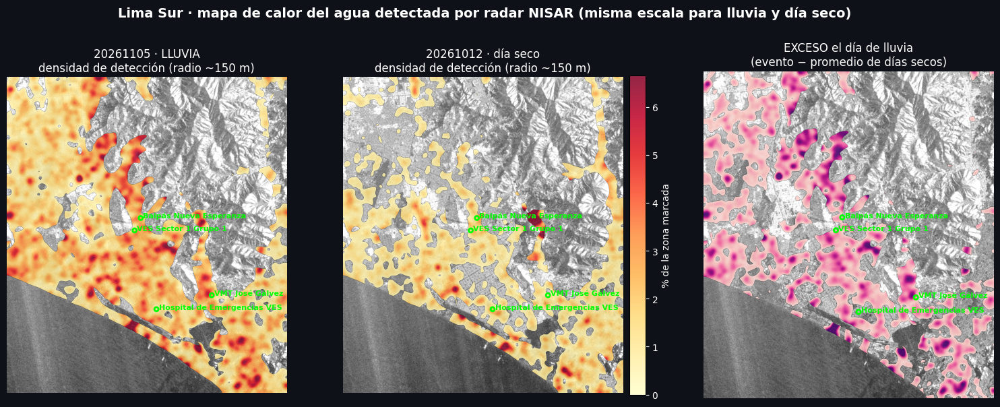

In [3]:
NOT = pd.DataFrame(META["noticias"])
def puntos(ax, caso):
    for _, r in NOT[NOT.caso == caso].iterrows():
        x, y = transformar_coord("EPSG:4326", CRS, [r.lon], [r.lat])
        f, c = rowcol(TRANSF, x[0], y[0])
        ax.add_patch(plt.Circle((c, f), 25, fill=False, color="lime", lw=2))
        ax.text(c + 30, f, r.lugar.split(" (")[0], color="lime", fontsize=8, weight="bold")
from scipy.ndimage import gaussian_filter
SIGMA_M = 150
def densidad(det):
    val = np.isfinite(det).astype("float32")
    num = gaussian_filter(np.nan_to_num(det == 1).astype("float32") * val, SIGMA_M / RES)
    den = gaussian_filter(val, SIGMA_M / RES)
    return np.where(den > 0.3, 100 * num / np.maximum(den, 1e-6), np.nan)
for caso, L in CAPAS.items():
    L["calor"] = densidad(L["deteccion"])
CONTROLES = [c for c in CAPAS if c.startswith("control")]
SECO_PROM = np.nanmean([CAPAS[c]["calor"] for c in CONTROLES], axis=0) if CONTROLES else np.zeros_like(CAPAS[EVENTO]["calor"])
EXCESO = CAPAS[EVENTO]["calor"] - SECO_PROM
VMAX_CALOR = max(float(np.nanpercentile(CAPAS[EVENTO]["calor"], 99.5)), 0.5)
VMAX_EXC = max(float(np.nanpercentile(EXCESO, 99.5)), 0.5)
print(f"escala del mapa de calor: 0–{VMAX_CALOR:.1f} % | exceso máx. (p99.5): {VMAX_EXC:.1f} puntos")
for caso, L in CAPAS.items():
    print(f"  {caso}: densidad media {np.nanmean(L['calor']):.2f} % | área con densidad > {VMAX_CALOR/3:.1f} %: "
          f"{np.nansum(L['calor'] > VMAX_CALOR / 3) * RES ** 2 / 1e6:.2f} km²")

casos_fig = [EVENTO] + CONTROLES[:1]
fig, ejes = plt.subplots(1, len(casos_fig) + 1, figsize=(6.3 * (len(casos_fig) + 1), 7), facecolor="#0e1117")
for ax, caso in zip(ejes, casos_fig):
    ax.imshow(CAPAS[caso]["fondo"], cmap="gray", vmin=-25, vmax=5)
    im = ax.imshow(np.ma.masked_less(np.nan_to_num(CAPAS[caso]["calor"]), VMAX_CALOR * 0.08), cmap="YlOrRd", vmin=0, vmax=VMAX_CALOR, alpha=0.85)
    ax.set_title(f"{CASOS[caso]['fecha']} · {'LLUVIA' if caso == EVENTO else 'día seco'}\ndensidad de detección (radio ~{SIGMA_M} m)", color="white")
ejes[-1].imshow(CAPAS[EVENTO]["fondo"], cmap="gray", vmin=-25, vmax=5)
ejes[-1].imshow(np.ma.masked_less(np.nan_to_num(EXCESO), VMAX_EXC * 0.15), cmap="RdPu", vmin=0, vmax=VMAX_EXC, alpha=0.9)
ejes[-1].set_title("EXCESO el día de lluvia\n(evento − promedio de días secos)", color="white")
for ax in ejes:
    ax.axis("off"); puntos(ax, EVENTO)
cb = fig.colorbar(im, ax=ejes[:-1], fraction=0.025, pad=0.01); cb.set_label("% de la zona marcada", color="white"); cb.ax.tick_params(colors="white")
fig.suptitle("Lima Sur · mapa de calor del agua detectada por radar NISAR (misma escala para lluvia y día seco)", color="white", fontsize=14, weight="bold")
plt.savefig(SALIDA / "mapa_calor.png", dpi=130, facecolor=fig.get_facecolor(), bbox_inches="tight"); plt.show()

## 2. Figura para la presentación: evento contra día seco (píxeles)

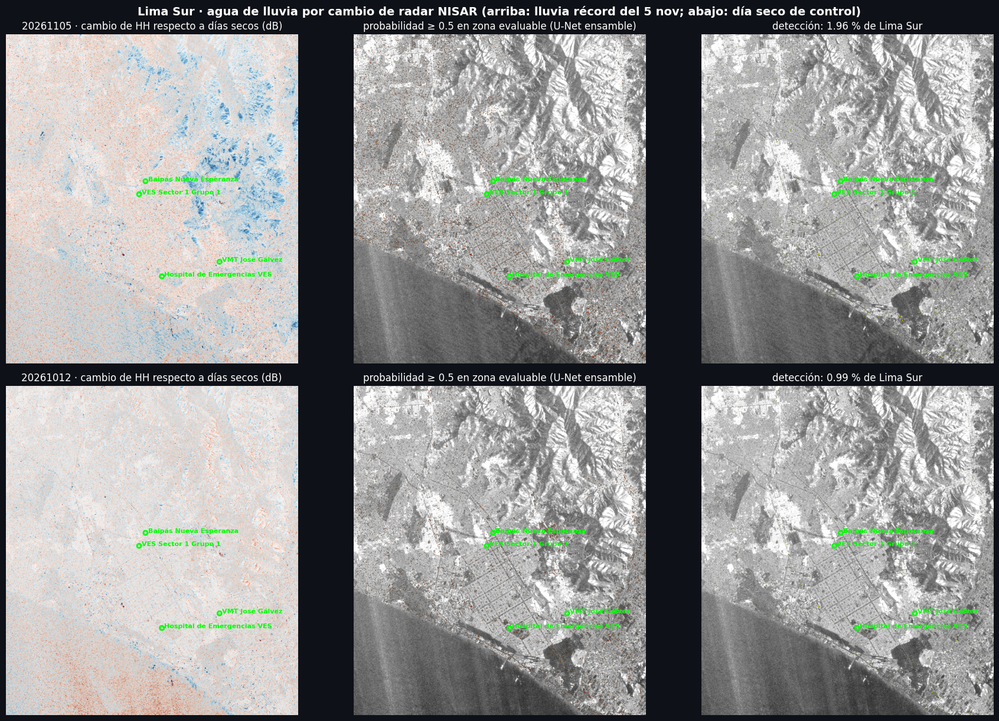

In [4]:
NOT = pd.DataFrame(META["noticias"])
def puntos(ax, caso):
    for _, r in NOT[NOT.caso == caso].iterrows():
        x, y = transformar_coord("EPSG:4326", CRS, [r.lon], [r.lat])
        f, c = rowcol(TRANSF, x[0], y[0])
        ax.add_patch(plt.Circle((c, f), 25, fill=False, color="lime", lw=2))
        ax.text(c + 30, f, r.lugar.split(" (")[0], color="lime", fontsize=8, weight="bold")

casos = [c for c in [EVENTO, CONTROL] if c in CAPAS]
fig, ejes = plt.subplots(len(casos), 3, figsize=(18, 6.2 * len(casos)), facecolor="#0e1117", squeeze=False)
for i, caso in enumerate(casos):
    L = CAPAS[caso]; fch = CASOS[caso]["fecha"]
    for ax in ejes[i]:
        ax.imshow(L["fondo"], cmap="gray", vmin=-25, vmax=5); ax.axis("off")
    ejes[i, 0].imshow(np.ma.masked_invalid(L["cambio"]), cmap="RdBu", vmin=-8, vmax=8, alpha=0.85)
    ejes[i, 0].set_title(f"{fch} · cambio de HH respecto a días secos (dB)", color="white")
    ejes[i, 1].imshow(np.ma.masked_less(np.nan_to_num(L["prob"]), 0.5), cmap="turbo", vmin=0, vmax=1, alpha=0.85)
    ejes[i, 1].set_title(f"probabilidad ≥ 0.5 en zona evaluable ({META['mejor_modelo']})", color="white")
    det = L["deteccion"] == 1
    ejes[i, 2].imshow(np.ma.masked_where(~det, det.astype(float)), cmap="autumn", vmin=0, vmax=1, alpha=0.95)
    ejes[i, 2].set_title(f"detección: {CASOS[caso]['pct_marcado']:.2f} % de Lima Sur", color="white")
    for ax in ejes[i]:
        puntos(ax, caso)
fig.suptitle("Lima Sur · agua de lluvia por cambio de radar NISAR (arriba: lluvia récord del 5 nov; abajo: día seco de control)",
             color="white", fontsize=14, weight="bold")
plt.tight_layout(); plt.savefig(SALIDA / "evento_vs_control.png", dpi=140, facecolor=fig.get_facecolor()); plt.show()

## 3. Mapa interactivo

evento_vs_control.png (5.8 MB)
mapa_calor.png (1.9 MB)
mapa_interactivo_final.html (12.4 MB)



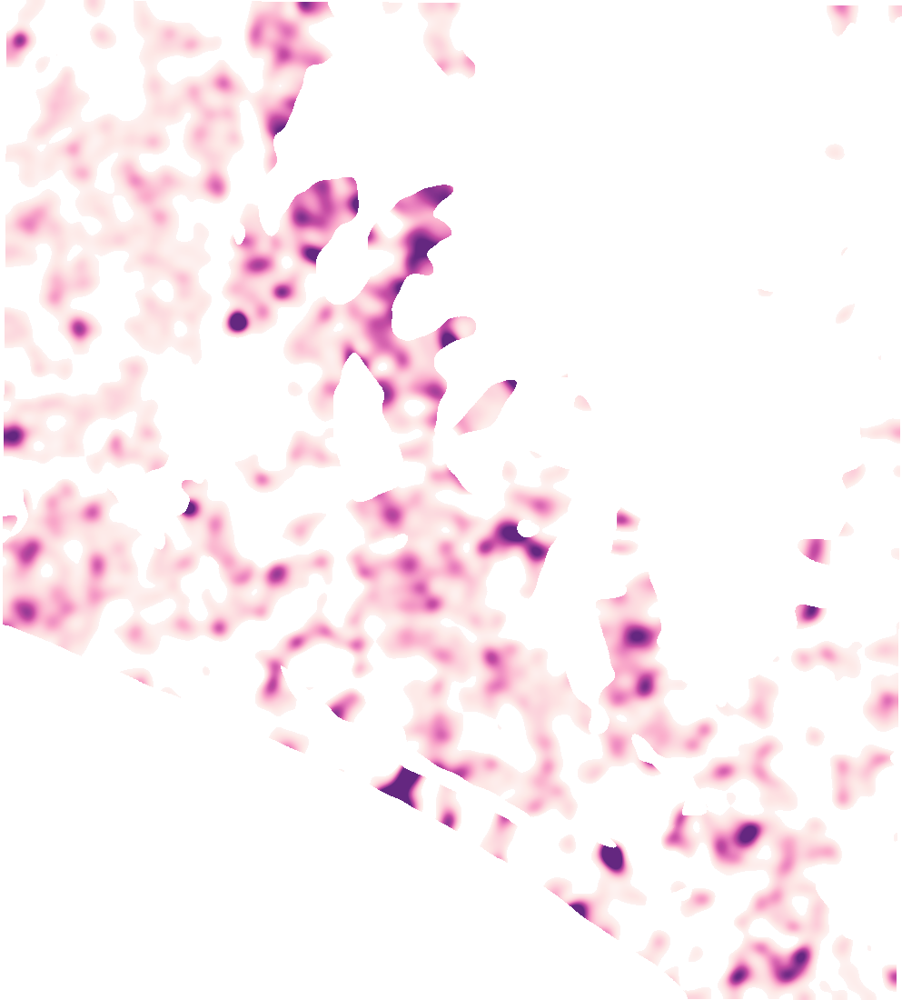
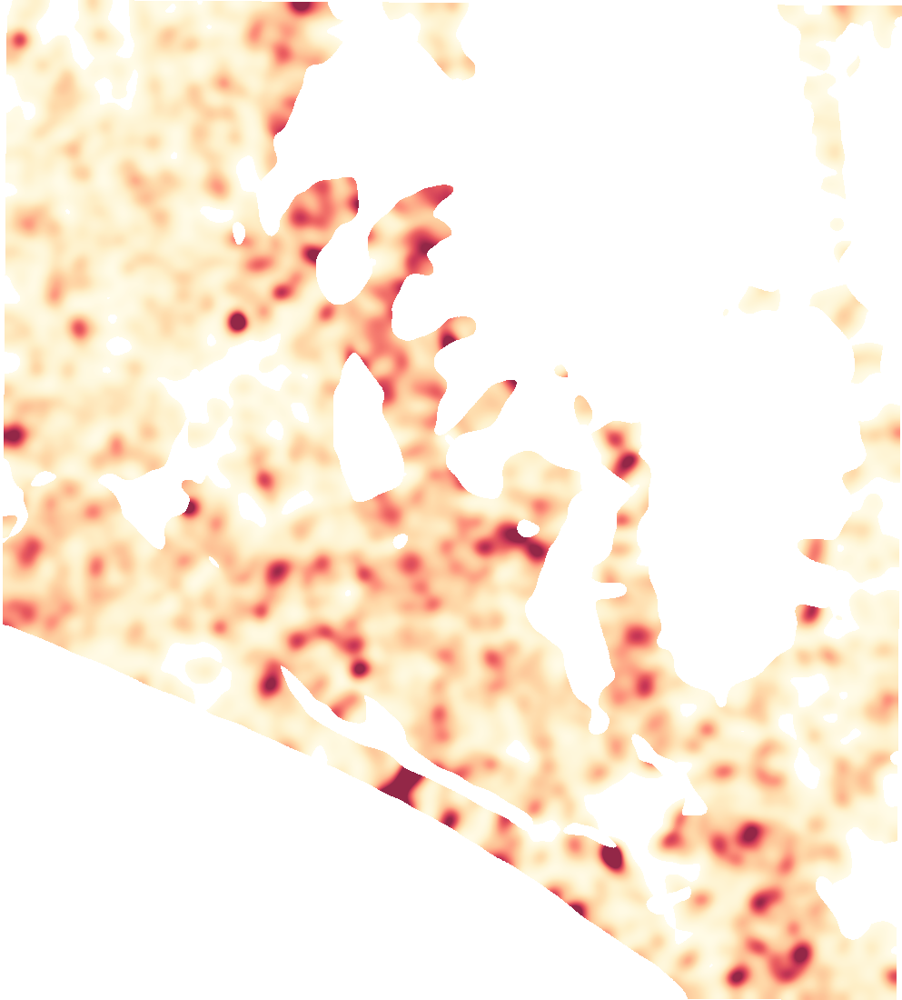
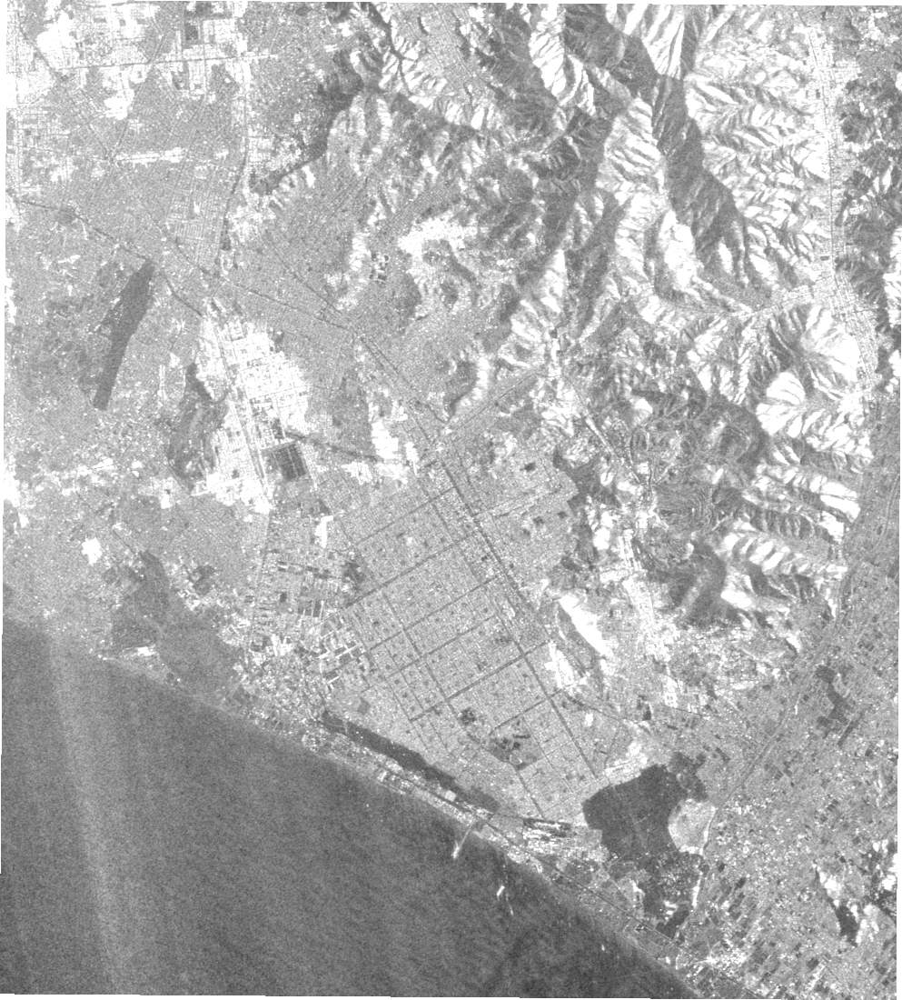
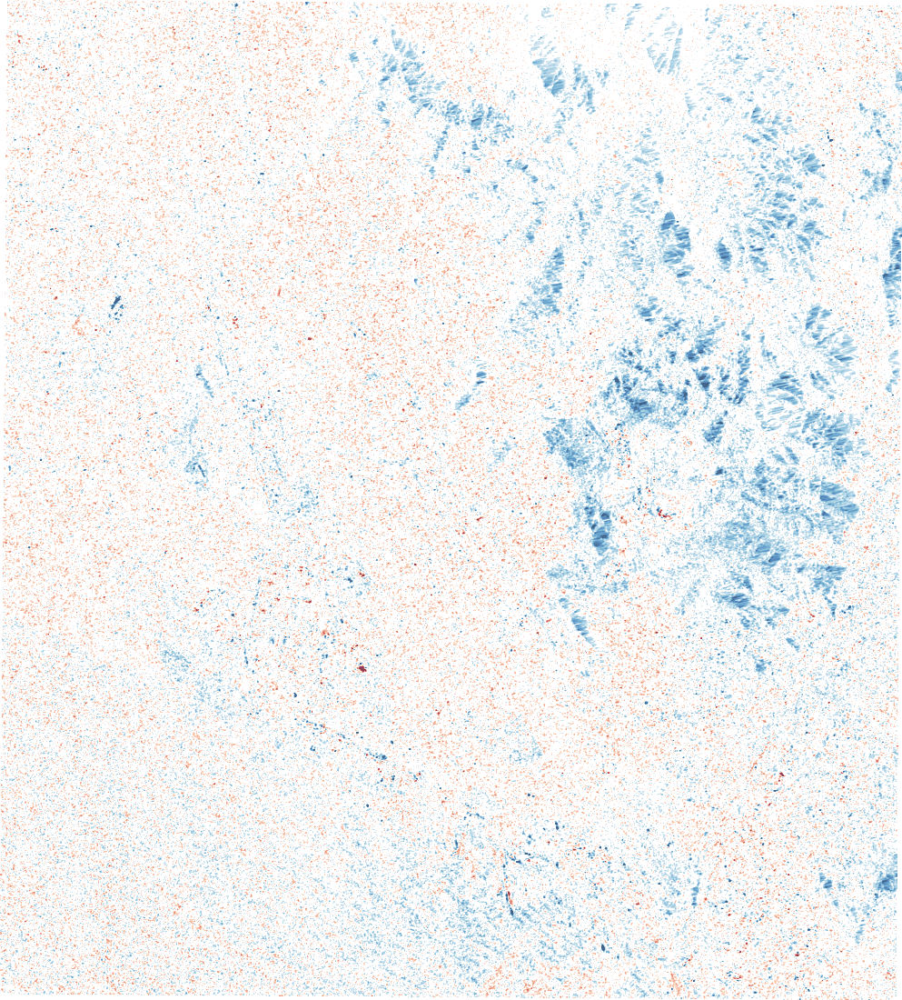
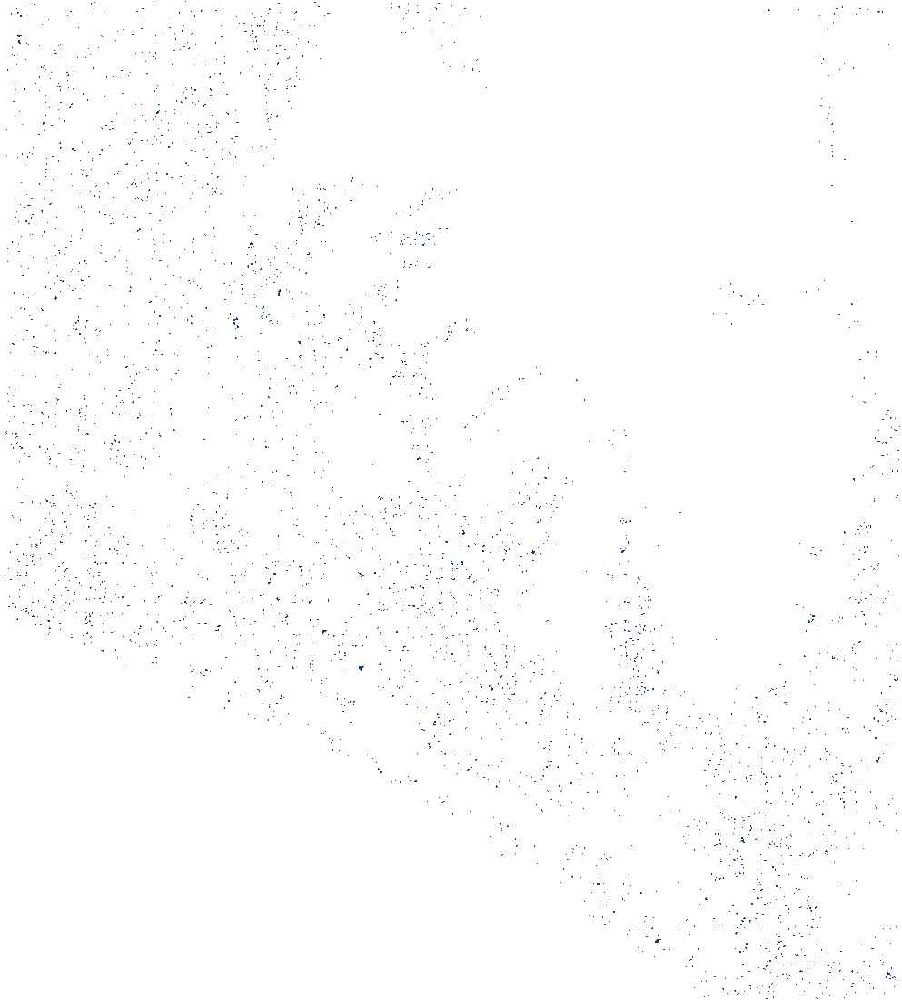
...
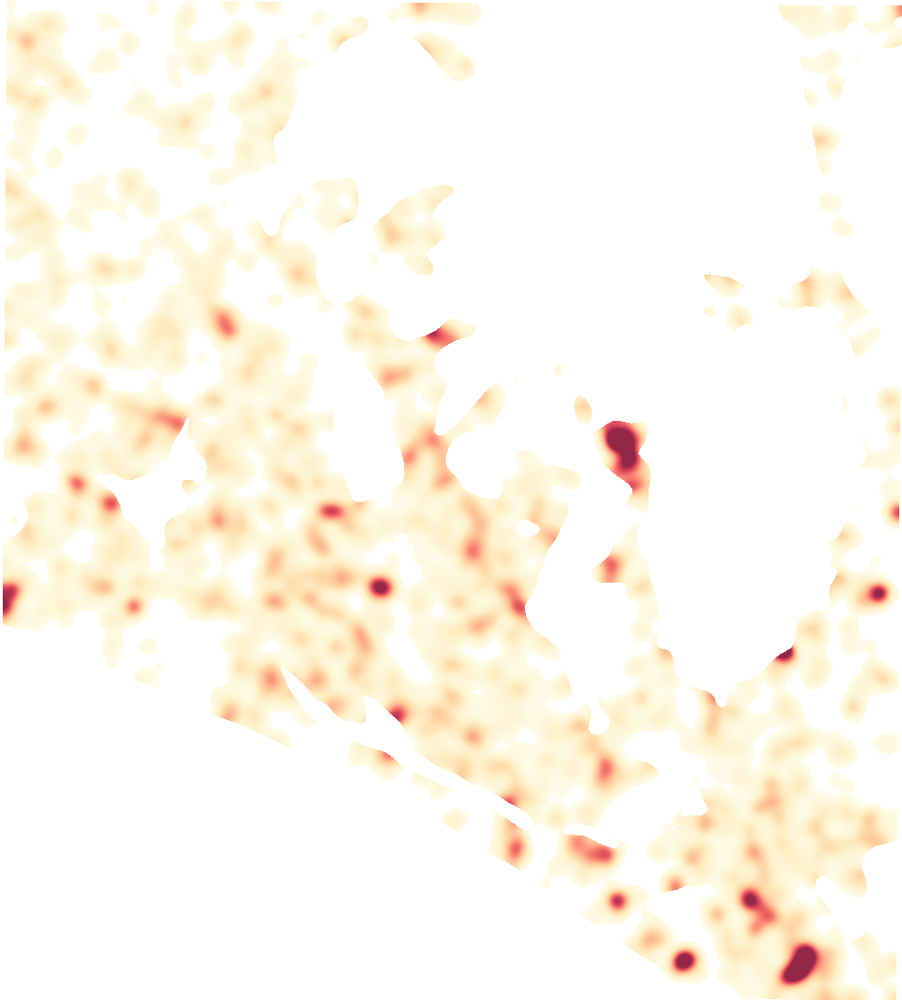
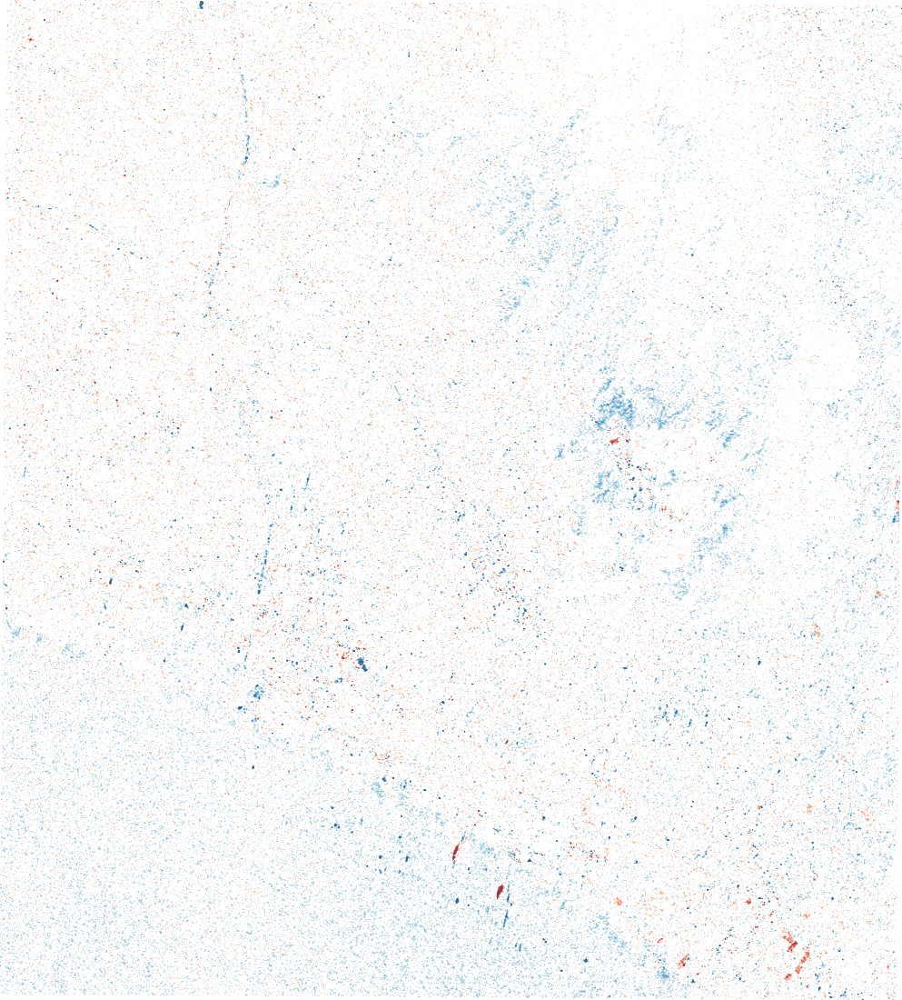
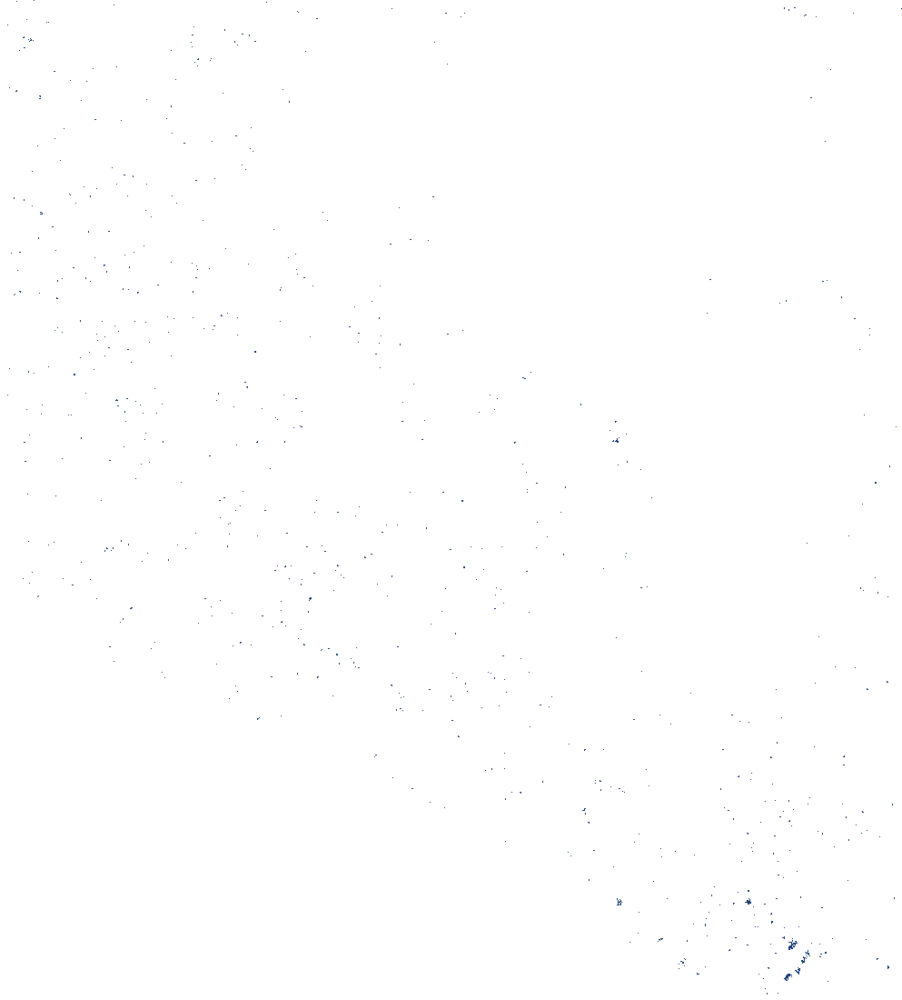
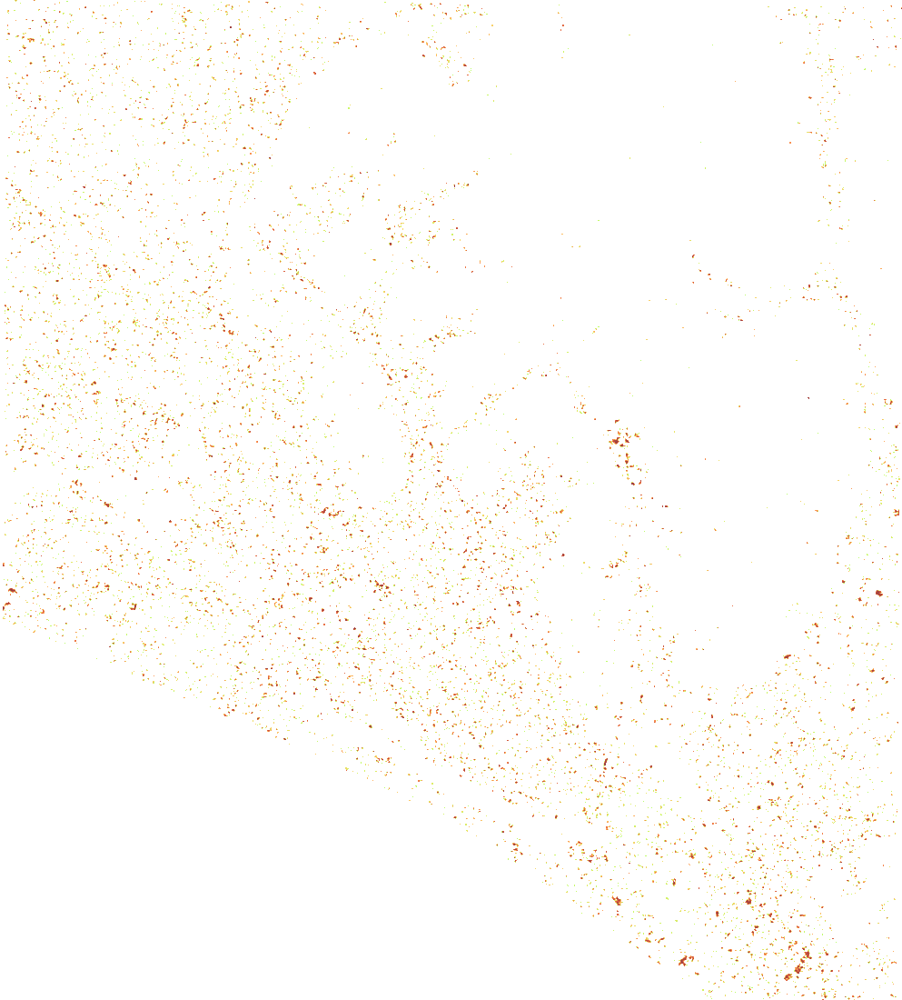
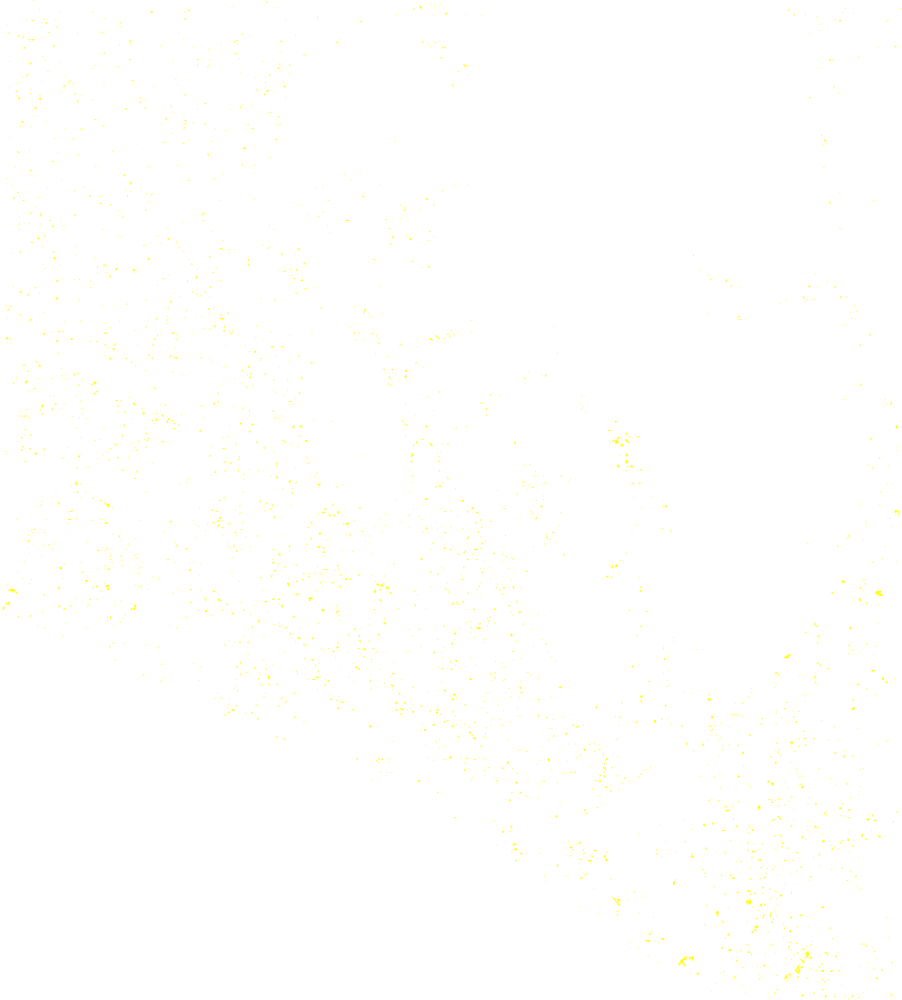

In [5]:
def a_wgs84(arr, max_lado=1100, metodo=Resampling.nearest):
    oeste, sur, este, norte = rasterio.transform.array_bounds(arr.shape[0], arr.shape[1], TRANSF)
    dst_t, w, h = calculate_default_transform(CRS, "EPSG:4326", arr.shape[1], arr.shape[0], left=oeste, bottom=sur, right=este, top=norte)
    esc = max(w, h) / max_lado
    if esc > 1:
        w, h = int(w / esc), int(h / esc); dst_t = dst_t * rasterio.Affine.scale(esc)
    out = np.full((h, w), np.nan, "float32")
    reproject(arr.astype("float32"), out, src_transform=TRANSF, src_crs=CRS, dst_transform=dst_t, dst_crs="EPSG:4326",
              resampling=metodo, src_nodata=np.nan, dst_nodata=np.nan)
    return out, [[dst_t.f + dst_t.e * h, dst_t.c], [dst_t.f, dst_t.c + dst_t.a * w]]

def capa_rgba(arr, cmap, vmin, vmax, mostrar, alfa=0.8):
    img, lim = arr
    t = np.clip((np.nan_to_num(img) - vmin) / (vmax - vmin), 0, 1)
    rgba = plt.get_cmap(cmap)(t)
    a = alfa(t) if callable(alfa) else alfa
    rgba[..., 3] = np.where(np.isfinite(img) & mostrar(img), a, 0)
    return (rgba * 255).astype("uint8"), lim

oeste, sur, este, norte = rasterio.transform.array_bounds(*CAPAS[EVENTO]["fondo"].shape, TRANSF)
lon, lat = transformar_coord(CRS, "EPSG:4326", [(oeste + este) / 2], [(sur + norte) / 2])
mapa = folium.Map(location=[lat[0], lon[0]], zoom_start=13, tiles=None, control_scale=True)
folium.TileLayer("OpenStreetMap", name="Calles (OpenStreetMap)").add_to(mapa)
folium.TileLayer("Esri.WorldImagery", name="Satélite (Esri)").add_to(mapa)

nombres_caso = {EVENTO: f"5 nov (lluvia)" if CASOS[EVENTO]["fecha"] == "20261105" else CASOS[EVENTO]["fecha"]}
if CONTROL: nombres_caso[CONTROL] = f"{CASOS[CONTROL]['fecha'][6:]}/{CASOS[CONTROL]['fecha'][4:6]} (seco)"
if "otro_evento" in CAPAS: nombres_caso["otro_evento"] = f"{CASOS['otro_evento']['fecha'][6:]}/{CASOS['otro_evento']['fecha'][4:6]} (lluvia, 2 días antes del pase)"

alfa_calor = lambda t: 0.25 + 0.6 * t
folium.raster_layers.ImageOverlay(capa_rgba(a_wgs84(EXCESO, metodo=Resampling.average), "RdPu", 0, VMAX_EXC, lambda a: a > VMAX_EXC * 0.15, alfa_calor)[0],
    bounds=a_wgs84(EXCESO)[1], name="★ Exceso el día de lluvia (5 nov − días secos)", show=False).add_to(mapa)
for caso in [c for c in [EVENTO, CONTROL, "otro_evento"] if c and c in CAPAS]:
    L = CAPAS[caso]
    etiqueta = nombres_caso.get(caso, caso); es_evento = caso == EVENTO
    capas = [
        (f"★ Mapa de calor · {etiqueta}", a_wgs84(L["calor"], metodo=Resampling.average), "YlOrRd", 0, VMAX_CALOR, lambda a: a > VMAX_CALOR * 0.08, alfa_calor, es_evento),
        (f"Radar HH · {etiqueta}", a_wgs84(L["fondo"], metodo=Resampling.average), "gray", -25, 5, lambda a: np.ones_like(a, bool), 0.9, False),
        (f"Cambio del radar (dB) · {etiqueta}", a_wgs84(L["cambio"], metodo=Resampling.average), "RdBu", -8, 8, lambda a: np.abs(a) > 1.5, 0.75, False),
        (f"Regla: agua nueva · {etiqueta}", a_wgs84(L["regla"]), "Blues", 0, 1, lambda a: a == 1, 0.95, False),
        (f"Probabilidad ({META['mejor_modelo']}) · {etiqueta}", a_wgs84(L["prob"], metodo=Resampling.average), "turbo", 0, 1, lambda a: a >= 0.5, 0.75, False),
        (f"Detección ({META['mejor_modelo']}) · {etiqueta}", a_wgs84(L["deteccion"]), "autumn", 0, 1, lambda a: a == 1, 0.95, False),
    ]
    if not es_evento:
        capas = [c for c in capas if not c[0].startswith("Radar HH")]      # el fondo de radar solo para el evento (archivo más liviano)
    for nombre, arr, cmap, vmin, vmax, mostrar, alfa, visible in capas:
        img, lim = capa_rgba(arr, cmap, vmin, vmax, mostrar, alfa)
        folium.raster_layers.ImageOverlay(img, bounds=lim, name=nombre, show=visible).add_to(mapa)

grupo = folium.FeatureGroup(name="Lugares reportados por la prensa", show=True)
ev_not = NOT[NOT.caso == EVENTO].set_index("lugar")
ct_not = NOT[NOT.caso == CONTROL].set_index("lugar") if CONTROL else None
for lugar, r in ev_not.iterrows():
    txt = (f"<b>{lugar}</b><br>Evento {CASOS[EVENTO]['fecha']}: cambio {r.cambio_db:+.2f} dB "
           f"(percentil {r.percentil:.0f} en la ciudad)")
    if ct_not is not None and lugar in ct_not.index:
        txt += f"<br>Día seco {CASOS[CONTROL]['fecha']}: cambio {ct_not.loc[lugar, 'cambio_db']:+.2f} dB (percentil {ct_not.loc[lugar, 'percentil']:.0f})"
    txt += "<br><i>Percentil bajo = se oscureció más que el resto de la ciudad (señal de agua)</i>"
    folium.Marker([r.lat, r.lon], popup=folium.Popup(txt, max_width=320), tooltip=lugar,
                  icon=folium.Icon(color="green", icon="tint", prefix="fa")).add_to(grupo)
grupo.add_to(mapa)

ce = CASOS[EVENTO]; cc = CASOS.get(CONTROL, {})
leyenda = f'''
<div style="position: fixed; bottom: 24px; left: 12px; z-index: 9999; background: rgba(255,255,255,0.93); padding: 10px 12px;
            border-radius: 8px; font: 12px/1.45 sans-serif; max-width: 320px; box-shadow: 0 1px 6px rgba(0,0,0,.3)">
<b>Agua de lluvia por cambio de radar NISAR · Lima Sur</b><br>
Mejor modelo: <b>{META['mejor_modelo']}</b><br>
Evento {ce['fecha']}: detecta <b>{ce['pct_marcado']:.2f} %</b> de Lima Sur (regla: {ce['pct_regla']:.2f} %)<br>
{"Día seco " + cc['fecha'] + f": detecta <b>{cc['pct_marcado']:.2f} %</b> (regla: {cc['pct_regla']:.2f} %)<br>" if cc else ""}
<span style="background:linear-gradient(90deg,#ffffb2,#fd8d3c,#bd0026);padding:0 18px"></span> mapa de calor: % marcado en ~150 m (0–{VMAX_CALOR:.0f} %, misma escala para todos los días)<br>
<span style="color:#c0392b">■</span> detección &nbsp; <span style="color:#2e86c1">■</span> regla &nbsp;
<span style="color:#b03a2e">■</span>/<span style="color:#2874a6">■</span> cambio −/+ dB
</div>'''
mapa.get_root().html.add_child(folium.Element(leyenda))
folium.LayerControl(collapsed=False).add_to(mapa)
mapa.save(SALIDA / "mapa_interactivo_final.html")
for p in sorted(SALIDA.iterdir()):
    print(f"{p.name} ({p.stat().st_size / 1e6:.1f} MB)")
mapa